# 解約を予測する：生存時間解析から施策の検証まで

## 概要

顧客が解約してから案内を送っても、すでに乗り換えを決めている場合がある。本記事では、『マーケティングサイエンスの理論と実践』第7章「解約を予測する」を紹介する。解約の課題、生存時間解析、Pythonによる解約スコアの算出、施策の効果と採算の確認を、本文の順に扱う。

## 実行環境

カーネルは **wa-src(3.14.6)**、Pythonは **3.14.6** である。上から順に実行する。図は `07_nb_files` にSVGで保存し、使用ライブラリのバージョンを下に表示する。再実行には同梱の `data/Telco-Customer-Churn.csv` と `requirements.txt` を使う。

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib_fontja
import numpy as np
import pandas as pd
from IPython.display import Latex, SVG, display
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import proportional_hazard_test
from matplotlib.ticker import FuncFormatter, ScalarFormatter
from scipy.stats import norm
from sklearn.metrics import (
    average_precision_score, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split

print(f"環境: wa-src(3.14.6) / Python {platform.python_version()}")
for package in (
    "numpy", "pandas", "scipy", "matplotlib", "matplotlib-fontja",
    "lifelines", "lightgbm", "scikit-learn",
):
    print(f"{package}: {version(package)}")

# リポジトリ内と、ダウンロードしたフォルダーの両方に対応する。
repo = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "doc/07/07_main.tex").exists()),
    None,
)
output_dir = repo / "blog/07" if repo else Path.cwd()
image_dir = output_dir / "07_nb_files"
image_dir.mkdir(parents=True, exist_ok=True)
data_path = output_dir / "data/Telco-Customer-Churn.csv"


def sig3(value):
    """表示だけを有効数字3桁にし、計算値は丸めない。"""
    return format(float(value), "#.3g")


np.set_printoptions(formatter={"float_kind": sig3})
pd.set_option("display.float_format", sig3)
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "svg.fonttype": "path", "svg.hashsalt": "blog07",
})
BLUE, ORANGE, GREEN = "#2c5f8a", "#b96532", "#3b795d"


def show_math(expression):
    # 重要な式の \(...\) を表示用の $$...$$ に変換する。
    # 出力はtext/latexであり、HTML内にインライン用の区切りを残さない。
    display(Latex(expression.replace(r"\(", "$$").replace(r"\)", "$$")))


def save_svg(fig, filename):
    """小数目盛りを3桁にそろえ、SVGを保存して出力欄に埋め込む。"""
    def tick_label(value, _):
        return str(int(value)) if value == int(value) else sig3(value)

    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                axis.set_major_formatter(FuncFormatter(tick_label))
        ax.grid(alpha=0.180)
        ax.set_axisbelow(True)
    fig.tight_layout()
    path = image_dir / filename
    fig.savefig(path, format="svg", bbox_inches="tight", metadata={"Date": None})
    display(SVG(filename=str(path)))
    plt.close(fig)

環境: wa-src(3.14.6) / Python 3.14.6
numpy: 2.4.6
pandas: 2.3.3
scipy: 1.18.1
matplotlib: 3.11.2
matplotlib-fontja: 1.1.0
lifelines: 0.30.3
lightgbm: 4.7.0
scikit-learn: 1.9.1


## 1. 誰に、いつ働きかけるか

新規顧客を獲得しても、既存顧客の解約が続けば契約者数は増えにくい。本章では、ログインの減少や支払いの遅延などから、解約前に対象者を見つける課題を考える。

「次の30日以内に解約するか」は分類問題、「契約から何か月後まで継続するか」は生存時間解析で扱う。$T_i$を解約までの期間、$\mathbf{x}_i^{(t)}$を現在$t$でわかる情報とすると、予測対象は次の条件付き確率になる。

In [2]:
show_math(r"\(p_{\mathrm{churn},i}=P(t<T_i\le t+\Delta t\mid T_i>t,\mathbf{x}_i^{(t)})\)")

<IPython.core.display.Latex object>

## 2. 生存時間解析で継続期間を扱う

### 2.1 継続中の顧客も使う

観測終了時に契約中の顧客は、解約時期がまだわからない。この右打ち切りを「解約しない」と確定させず、そこまで継続した情報として使う。$C_i$を観測できる期間、$t_i$を実際の観測期間、$\delta_i$を解約の有無とする。起点は各顧客の契約開始日である。

<IPython.core.display.Latex object>

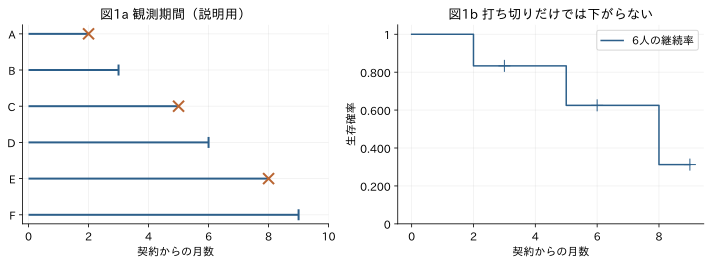

In [3]:
show_math(r"\(t_i=\min(T_i,C_i),\qquad\delta_i=\begin{cases}1&T_i\le C_i\\0&T_i>C_i\end{cases}\)")

# 6人の説明用データ。×は解約、縦線は右打ち切りを示す。
toy_time = np.array([2, 3, 5, 6, 8, 9])
toy_event = np.array([1, 0, 1, 0, 1, 0])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for i, (duration, event) in enumerate(zip(toy_time, toy_event)):
    axes[0].hlines(i, 0, duration, color=BLUE, linewidth=2)
    axes[0].plot(duration, i, "x" if event else "|",
                 color=ORANGE if event else BLUE, markersize=11, markeredgewidth=2)
axes[0].set(yticks=range(6), yticklabels=list("ABCDEF"), xlabel="契約からの月数",
            title="図1a 観測期間（説明用）", xlim=(-0.200, 10))
axes[0].invert_yaxis()
toy_km = KaplanMeierFitter().fit(toy_time, toy_event, label="6人の継続率")
toy_km.plot_survival_function(ax=axes[1], ci_show=False, show_censors=True, color=BLUE)
axes[1].set(xlabel="契約からの月数", ylabel="生存確率", ylim=(0, 1.05),
            title="図1b 打ち切りだけでは下がらない")
save_svg(fig, "01_censoring.svg")

### 2.2 カプラン・マイヤー曲線

生存関数$S(t)=P(T>t)$は、$t$を過ぎても継続する確率である。カプラン・マイヤー推定では、解約時点$t_j$の直前に観測対象だった$n_j$人から、解約した$d_j$人を除いた割合を順に掛ける。打ち切りと解約が独立とみなせる条件が必要である。

本文の計算例では、1か月目の対象は1,000人、解約は50人、打ち切りは10人である。2か月目の対象は940人になり、80人が解約する。打ち切りは翌月の分母に反映される。

In [4]:
show_math(r"""\(\begin{aligned}
\widehat S(t)&=\prod_{j:t_j\le t}\left(1-\frac{d_j}{n_j}\right)\\
\widehat S(1)&=1-\frac{50}{1000}=\frac{950}{1000}=0.950\\
n_2&=1000-50-10=940\\
\widehat S(2)&=\frac{950}{1000}\left(1-\frac{80}{940}\right)
=\frac{950}{1000}\frac{860}{940}\approx0.869
\end{aligned}\)""")
survival = np.cumprod(1 - np.array([50, 80]) / np.array([1000, 940]))
pprint({"1か月後": sig3(survival[0]), "2か月後": sig3(survival[1])})

<IPython.core.display.Latex object>

{'1か月後': '0.950', '2か月後': '0.869'}


### 2.3 ハザードとCoxモデル

ハザード$h(t)$は、その時点まで継続した顧客の直後の解約しやすさを、単位時間当たりで表す。確率そのものではない。連続時間で$S(0)=1$とし、$S(t)>0$の範囲で式を変形する。$f(t)$は解約時期の密度、$H(t)$は累積ハザードである。

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

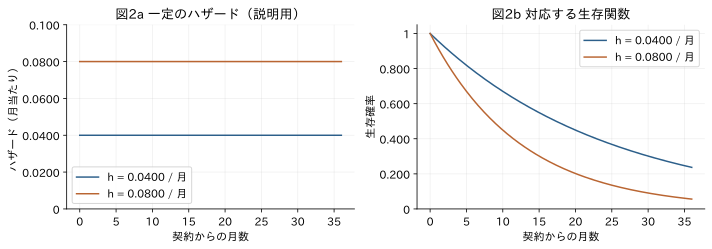

In [5]:
show_math(r"""\(\begin{aligned}
h(t)&=\lim_{\Delta t\to0}\frac{P(t<T\le t+\Delta t\mid T>t)}{\Delta t}\\
&=\lim_{\Delta t\to0}\frac{S(t)-S(t+\Delta t)}{S(t)\Delta t}
=-\frac{S'(t)}{S(t)}=\frac{f(t)}{S(t)}\\
\frac{d}{dt}\log S(t)&=-h(t)\\
\log S(t)-\log S(0)&=-\int_0^t h(u)\,du=-H(t)\\
S(t)&=\exp[-H(t)]
\end{aligned}\)""")
show_math(r"""\(\begin{aligned}
P(t<T\le t+\Delta t\mid T>t)
&=\frac{S(t)-S(t+\Delta t)}{S(t)}\\
&=1-\frac{S(t+\Delta t)}{S(t)}\\
&=1-\exp\left[-\int_t^{t+\Delta t}h(u)\,du\right]
\end{aligned}\)""")

# 一定ハザードを仮定した説明用の曲線。実データの推定値ではない。
months = np.linspace(0, 36, 181)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for rate, color in [(0.0400, BLUE), (0.0800, ORANGE)]:
    label = f"h = {sig3(rate)} / 月"
    axes[0].plot(months, np.full_like(months, rate), color=color, label=label)
    axes[1].plot(months, np.exp(-rate * months), color=color, label=label)
axes[0].set(title="図2a 一定のハザード（説明用）", ylabel="ハザード（月当たり）", ylim=(0, 0.100))
axes[1].set(title="図2b 対応する生存関数", ylabel="生存確率", ylim=(0, 1.05))
for ax in axes:
    ax.set_xlabel("契約からの月数")
    ax.legend()
save_svg(fig, "02_hazard_survival.svg")

Coxモデルは、基準のハザード$h_0(t)$に、顧客の特徴$\mathbf{x}_i$による倍率を掛ける。$\mathbf{b}$は係数ベクトルである。2人の比では$h_0(t)$が消えるため、比が時間によらず一定という仮定になる。

In [6]:
show_math(r"""\(\begin{aligned}
h(t\mid\mathbf{x}_i)&=h_0(t)\exp(\mathbf{b}^{\mathsf T}\mathbf{x}_i)\\
\frac{h(t\mid\mathbf{x}_i)}{h(t\mid\mathbf{x}_j)}
&=\frac{h_0(t)\exp(\mathbf{b}^{\mathsf T}\mathbf{x}_i)}
{h_0(t)\exp(\mathbf{b}^{\mathsf T}\mathbf{x}_j)}\\
&=\exp[\mathbf{b}^{\mathsf T}(\mathbf{x}_i-\mathbf{x}_j)]\\
\mathrm{HR}_k&=\exp(b_k)
\end{aligned}\)""")
show_math(r"""\(\begin{aligned}
\mathcal R(t_j)&=\{k:t_k\ge t_j\}\\
L(\mathbf{b})&=\prod_{j:\delta_j=1}
\frac{\exp(\mathbf{b}^{\mathsf T}\mathbf{x}_j)}
{\sum_{k\in\mathcal R(t_j)}\exp(\mathbf{b}^{\mathsf T}\mathbf{x}_k)}\\
\log L(\mathbf{b})&=\sum_{j:\delta_j=1}\left[
\mathbf{b}^{\mathsf T}\mathbf{x}_j-
\log\sum_{k\in\mathcal R(t_j)}\exp(\mathbf{b}^{\mathsf T}\mathbf{x}_k)\right]
\end{aligned}\)""")

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

他の項目を固定して$x_k$が1増えると、ハザードは$\exp(b_k)$倍になる。期間内の解約確率が同じ倍率になるわけではない。係数は、解約直前まで観測された顧客の集合$\mathcal R(t_j)$を使う部分尤度$L$から求める。上式は同時解約がない場合で、月次データの同時解約には実装内のEfron法を使う。

## 3. Pythonで継続率と関連要因を調べる

### 3.1 データの準備

本章と同じIBM Telcoデータ7,043人を使う。`tenure`を観測月数、`Churn`を解約の有無とする。ただし、契約開始日や解約日がなく、観測期間の作り方は確認できない。以下は生存時間解析の手順例である。`TotalCharges`の欠損11件は、モデルで使わないため行ごと削除しない。

顧客数: 7,043人 / 解約: 1,869人
解約割合: 26.5%
TotalChargesの欠損: 11件
                  人数   解約割合
Contract                   
Month-to-month  3875  0.427
One year        1473  0.113
Two year        1695 0.0283


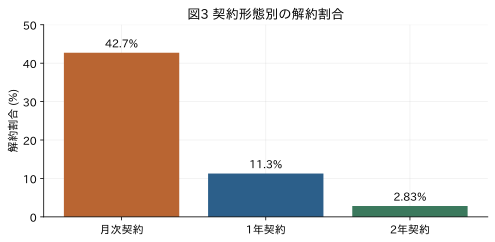

In [7]:
use_cols = [
    "customerID", "tenure", "Churn", "MonthlyCharges", "TotalCharges",
    "Contract", "InternetService", "PaymentMethod", "SeniorCitizen",
    "Partner", "TechSupport",
]
df = pd.read_csv(data_path, usecols=use_cols)
df["churn_flag"] = df["Churn"].eq("Yes").astype(int)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
T = df["tenure"].to_numpy()
E = df["churn_flag"].to_numpy()
print(f"顧客数: {len(df):,}人 / 解約: {df['churn_flag'].sum():,}人")
print(f"解約割合: {sig3(100 * df['churn_flag'].mean())}%")
print(f"TotalChargesの欠損: {df['TotalCharges'].isna().sum()}件")

contracts = ["Month-to-month", "One year", "Two year"]
contract_labels = ["月次契約", "1年契約", "2年契約"]
contract_summary = df.groupby("Contract")["churn_flag"].agg(["size", "mean"]).reindex(contracts)
print(contract_summary.rename(columns={"size": "人数", "mean": "解約割合"}).to_string())
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(contract_labels, 100 * contract_summary["mean"], color=[ORANGE, BLUE, GREEN])
ax.bar_label(bars, labels=[f"{sig3(v)}%" for v in 100 * contract_summary["mean"]], padding=4)
ax.set(title="図3 契約形態別の解約割合", ylabel="解約割合 (%)", ylim=(0, 50))
save_svg(fig, "03_churn_by_contract.svg")

### 3.2 カプラン・マイヤー曲線の比較

図3の集計には在籍期間の違いが反映されていない。次に全体と契約形態別の生存曲線を描き、同じ在籍月数で比較する。全体の帯は95%信頼区間である。

月次契約: 12か月生存確率 = 0.703
1年契約: 12か月生存確率 = 0.991
2年契約: 12か月生存確率 = 1.00


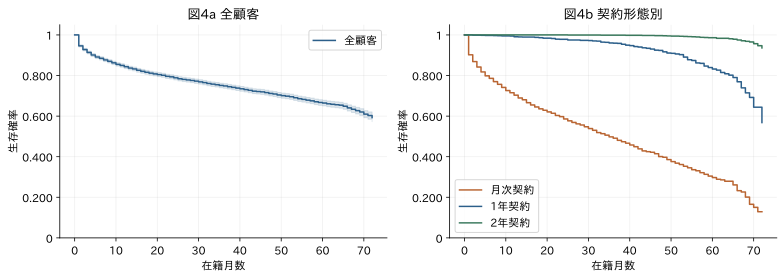

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
km = KaplanMeierFitter().fit(T, E, label="全顧客")
km.plot_survival_function(ax=axes[0], color=BLUE, ci_alpha=0.150)
for contract, label, color in zip(contracts, contract_labels, [ORANGE, BLUE, GREEN]):
    group = df.loc[df["Contract"].eq(contract)]
    group_km = KaplanMeierFitter().fit(group["tenure"], group["churn_flag"], label=label)
    group_km.plot_survival_function(ax=axes[1], ci_show=False, color=color)
    print(f"{label}: 12か月生存確率 = {sig3(group_km.predict(12))}")
for ax, title in zip(axes, ["図4a 全顧客", "図4b 契約形態別"]):
    ax.set(title=title, xlabel="在籍月数", ylabel="生存確率", ylim=(0, 1.05))
save_svg(fig, "04_kaplan_meier.svg")

月次契約は早い時期から曲線が低下する。ただし、この差だけでは、長期契約への変更が解約を減らすとは判断できない。長く使う予定の顧客が長期契約を選んでいる可能性もある。

### 3.3 Coxモデルの推定

契約形態などを0・1の列に変換し、係数が極端にならないよう正則化を加える。図5は係数と95%信頼区間であり、正ならハザードが高い方向、負なら低い方向を示す。契約形態の基準は月次契約である。

比例ハザードの検定でp値が0.0500未満の項目: 7


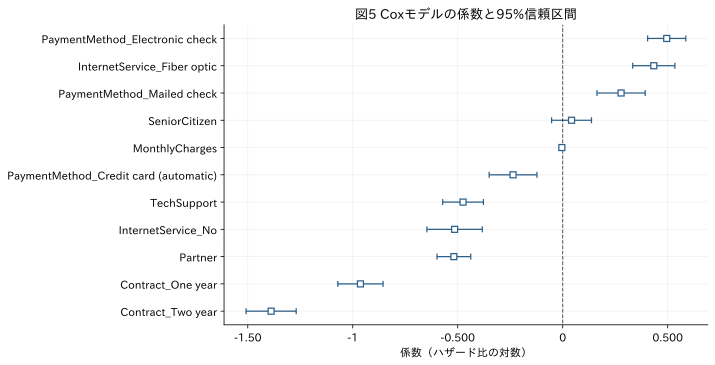

In [9]:
cox_cols = [
    "tenure", "churn_flag", "MonthlyCharges", "SeniorCitizen", "Contract",
    "InternetService", "PaymentMethod", "Partner", "TechSupport",
]
cox_data = pd.get_dummies(
    df[cox_cols], columns=["Contract", "InternetService", "PaymentMethod"],
    drop_first=True, dtype=int,
)
for name in ["Partner", "TechSupport"]:
    cox_data[name] = cox_data[name].eq("Yes").astype(int)

cox = CoxPHFitter(penalizer=0.100)
cox.fit(cox_data, duration_col="tenure", event_col="churn_flag")
ph = proportional_hazard_test(cox, cox_data, time_transform="rank")
ph_count = int(ph.summary["p"].lt(0.0500).sum())
print(f"比例ハザードの検定でp値が0.0500未満の項目: {ph_count}")

fig, ax = plt.subplots(figsize=(10, 5.2))
cox.plot(ax=ax, c=BLUE)
ax.set(title="図5 Coxモデルの係数と95%信頼区間", xlabel="係数（ハザード比の対数）")
save_svg(fig, "05_cox_coefficients.svg")

今回、比例ハザードの検定では7項目で$p<0.0500$となった。係数は全期間をまとめた参考値として読む。実務では時間による変化も調べ、必要なら期間や顧客群を分ける。私は、係数の大小を見る前に、この仮定を確認しておきたい。

## 4. LightGBMで対象候補を並べる

### 4.1 学習と評価

本データの`Churn`は観測時点の状態であり、将来の30日間を表す正解ではない。出力は観測時点の解約を見分けるスコアとして扱う。本文と同じ特徴量を使い、学習・検証・テストを60%・20%・20%に分ける。実務では基準日までの情報で将来の解約を予測し、後の期間で評価する。

学習 4225件 / 検証 1409件 / テスト 1409件


{'テストAP': '0.623', 'テストROC-AUC': '0.830', '最適な学習回数': 61, '無作為順位のAPの目安': '0.265'}


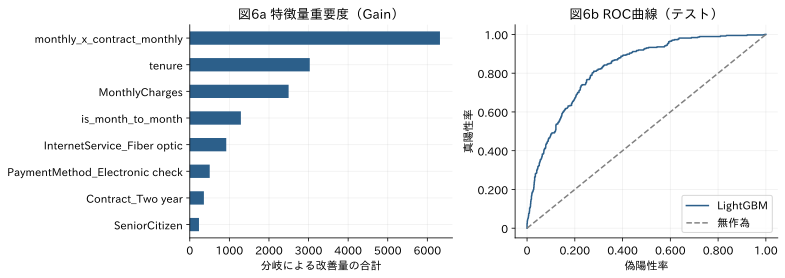

In [10]:
# Cox用の数値化を再利用し、分類用に在籍月数と追加の特徴量を使う。
X = cox_data.drop(columns="churn_flag").copy()
X["is_early_tenure"] = X["tenure"].between(1, 3).astype(int)
X["is_month_to_month"] = df["Contract"].eq("Month-to-month").astype(int)
X["monthly_x_contract_monthly"] = X["MonthlyCharges"] * X["is_month_to_month"]
y = df["churn_flag"]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.400, random_state=42, stratify=y,
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.500, random_state=42, stratify=y_temp,
)
print(f"学習 {len(X_train)}件 / 検証 {len(X_val)}件 / テスト {len(X_test)}件")

# 検証データだけを使って学習の停止時点を決める。
params = {
    "objective": "binary", "metric": ["auc", "binary_logloss"],
    "learning_rate": 0.0500, "num_leaves": 31, "min_child_samples": 20,
    "feature_fraction": 0.800, "bagging_fraction": 0.800, "bagging_freq": 5,
    "reg_alpha": 0.100, "reg_lambda": 0.100, "verbosity": -1,
    "seed": 42, "num_threads": 1, "deterministic": True, "force_col_wise": True,
}
model = lgb.train(
    params, lgb.Dataset(X_train, label=y_train), num_boost_round=500,
    valid_sets=[lgb.Dataset(X_val, label=y_val)],
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
val_score = model.predict(X_val)
test_score = model.predict(X_test)
pprint({
    "最適な学習回数": model.best_iteration,
    "テストROC-AUC": sig3(roc_auc_score(y_test, test_score)),
    "テストAP": sig3(average_precision_score(y_test, test_score)),
    "無作為順位のAPの目安": sig3(y_test.mean()),
})

importance = pd.Series(model.feature_importance("gain"), index=X.columns).nlargest(8)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
importance.sort_values().plot.barh(ax=axes[0], color=BLUE)
axes[0].set(title="図6a 特徴量重要度（Gain）", xlabel="分岐による改善量の合計")
false_positive, true_positive, _ = roc_curve(y_test, test_score)
axes[1].plot(false_positive, true_positive, color=BLUE, label="LightGBM")
axes[1].plot([0, 1], [0, 1], "--", color="0.500", label="無作為")
axes[1].set(title="図6b ROC曲線（テスト）", xlabel="偽陽性率", ylabel="真陽性率")
axes[1].legend()
save_svg(fig, "06_model_evaluation.svg")

ROC-AUCは解約者を高く並べる力、APは適合率と再現率の関係を要約する指標である。APは解約割合によって比較の基準が変わる。特徴量重要度は予測に使われた程度であり、解約の原因や影響の向きは示さない。

### 4.2 閾値と対象人数

TPは正しく選んだ解約者、FPは選んだ継続者、FNは見逃した解約者の数である。F1は適合率と再現率の調和平均になる。候補の閾値は検証データで決め、テストでは固定する。

<IPython.core.display.Latex object>

{'テストF1': '0.604',
 'テストの対象候補数': 460,
 'テスト再現率': '0.674',
 'テスト適合率': '0.548',
 '検証で選んだ閾値': '0.359'}


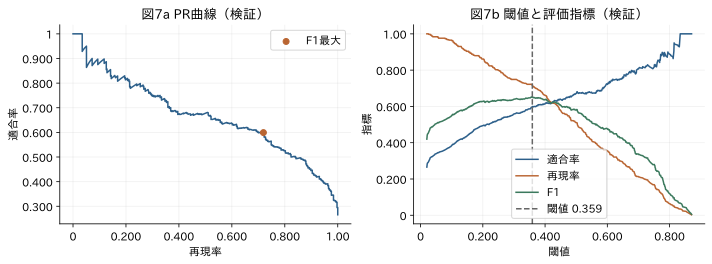

customerID  churn_score  actual_churn
9300-AGZNL        0.866             1
6567-HOOPW        0.863             1
7493-TPUWZ        0.860             1
2514-GINMM        0.860             1
0495-RVCBF        0.860             1


In [11]:
show_math(r"""\(\begin{aligned}
P&=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FP}},\qquad
R=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}}\\
F_1&=\frac{2}{1/P+1/R}
=\frac{2PR}{P+R}
=\frac{2\mathrm{TP}}{2\mathrm{TP}+\mathrm{FP}+\mathrm{FN}}
\end{aligned}\)""")
precision, recall, thresholds = precision_recall_curve(y_val, val_score)
denominator = precision[:-1] + recall[:-1]
f1 = np.divide(2 * precision[:-1] * recall[:-1], denominator,
               out=np.zeros_like(denominator), where=denominator > 0)
best = int(np.argmax(f1))
threshold = thresholds[best]
test_selected = test_score >= threshold
pprint({
    "検証で選んだ閾値": sig3(threshold),
    "テスト適合率": sig3(precision_score(y_test, test_selected)),
    "テスト再現率": sig3(recall_score(y_test, test_selected)),
    "テストF1": sig3(f1_score(y_test, test_selected)),
    "テストの対象候補数": int(test_selected.sum()),
})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(recall, precision, color=BLUE)
axes[0].scatter(recall[best], precision[best], color=ORANGE, zorder=3, label="F1最大")
axes[0].set(title="図7a PR曲線（検証）", xlabel="再現率", ylabel="適合率")
for values, label, color in zip([precision[:-1], recall[:-1], f1],
                                ["適合率", "再現率", "F1"], [BLUE, ORANGE, GREEN]):
    axes[1].plot(thresholds, values, label=label, color=color)
axes[1].axvline(threshold, color="0.400", linestyle="--", label=f"閾値 {sig3(threshold)}")
axes[1].set(title="図7b 閾値と評価指標（検証）", xlabel="閾値", ylabel="指標")
for ax in axes:
    ax.legend()
save_svg(fig, "07_threshold.svg")

# これは評価用の対象候補。actual_churnは運用時のリストには入れない。
evaluation = pd.DataFrame({
    "customerID": df.loc[X_test.index, "customerID"],
    "churn_score": test_score, "actual_churn": y_test,
}).sort_values("churn_score", ascending=False, kind="stable")
candidates = evaluation.loc[evaluation["churn_score"].ge(threshold)]
print(candidates.head(5).to_string(index=False, float_format=sig3))

F1最大は採算の最適点とは限らない。対応できる人数が決まっている場合は、上位から何人選ぶと解約者の何割を含むかを確認する。累積ゲインはその割合、リフトは無作為に選ぶ場合との倍率である。

<IPython.core.display.Latex object>

{'リフト': '2.39', '上位約20%の人数': 282, '解約者の捕捉割合': '0.479'}


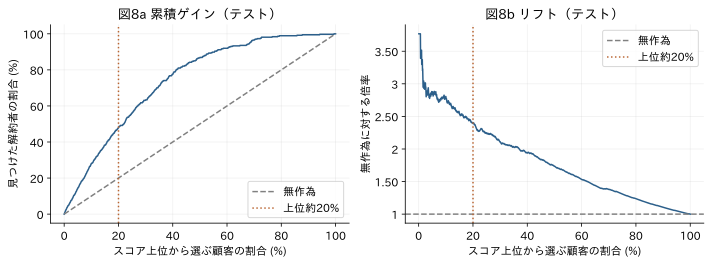

In [12]:
show_math(r"\(\mathrm{Gain}(k)=\frac{\text{上位}k\text{人に含まれる解約者数}}{\text{全解約者数}},\qquad\mathrm{Lift}(k)=\frac{\mathrm{Gain}(k)}{k/N}\)")
labels = evaluation["actual_churn"].to_numpy()
fraction = np.arange(1, len(labels) + 1) / len(labels)
gain = np.cumsum(labels) / labels.sum()
lift = gain / fraction
k = int(np.ceil(0.200 * len(labels)))
pprint({"上位約20%の人数": k, "解約者の捕捉割合": sig3(gain[k - 1]),
        "リフト": sig3(lift[k - 1])})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(np.r_[0, fraction * 100], np.r_[0, gain * 100], color=BLUE)
axes[0].plot([0, 100], [0, 100], "--", color="0.500", label="無作為")
axes[0].set(title="図8a 累積ゲイン（テスト）", ylabel="見つけた解約者の割合 (%)")
axes[1].plot(fraction * 100, lift, color=BLUE)
axes[1].axhline(1, color="0.500", linestyle="--", label="無作為")
axes[1].set(title="図8b リフト（テスト）", ylabel="無作為に対する倍率")
for ax in axes:
    ax.axvline(fraction[k - 1] * 100, color=ORANGE, linestyle=":", label="上位約20%")
    ax.set_xlabel("スコア上位から選ぶ顧客の割合 (%)")
    ax.legend()
save_svg(fig, "08_gain_lift.svg")

### 4.3 施策の効果と採算を確かめる

対象候補が決まっても、案内で解約を減らせるかは別に確かめる。本文の仮想的なA/Bテストでは、契約中の対象者を無作為に1,000人ずつ分け、3か月の解約が通常対応で200人、施策ありで150人だったとする。これはTelcoデータの分析結果ではない。

解約率の差は5ポイントで、増えた継続人数の推定は50人になる。継続した850人全員を施策の成果とは数えない。独立な2群の比率の差を正規近似し、95%信頼区間も計算する。

In [13]:
show_math(r"""\(\begin{aligned}
\widehat r_C&=\frac{200}{1000}=0.200,\qquad
\widehat r_T=\frac{150}{1000}=0.150\\
\widehat{\Delta r}&=0.200-0.150=0.0500,\qquad
N\widehat{\Delta r}=1000\times0.0500=50\\
\mathrm{SE}&=\sqrt{\frac{0.200(1-0.200)}{1000}
+\frac{0.150(1-0.150)}{1000}}\approx0.0170\\
\mathrm{CI}_{95\%}&=\widehat{\Delta r}\pm z_{0.975}\mathrm{SE}
\approx[0.0168,\ 0.0832]
\end{aligned}\)""")
# 仮想実験の集計値から計算する。途中の値は丸めない。
n = 1000
rate_control, rate_treatment = 200 / n, 150 / n
delta = rate_control - rate_treatment
se = np.sqrt(rate_control * (1 - rate_control) / n
             + rate_treatment * (1 - rate_treatment) / n)
ci = delta + np.array([-1, 1]) * norm.ppf(0.975) * se
pprint({"改善幅の95%信頼区間（ポイント）": [sig3(v * 100) for v in ci]})

<IPython.core.display.Latex object>

{'改善幅の95%信頼区間（ポイント）': ['1.68', '8.32']}


継続が増えた1件当たりの追加粗利の現在価値$g$を2万円、対象者1人当たりの費用$c$を500円と仮定する。粗利は今後12か月分で、今回の3か月の比較から直接求めた値ではない。施策費用は対象者全員に掛かる。

<IPython.core.display.Latex object>

{'利益の試算（円）': '500,000', '改善幅の区間に対応する利益の幅（万円）': ['-16.5', '116.']}


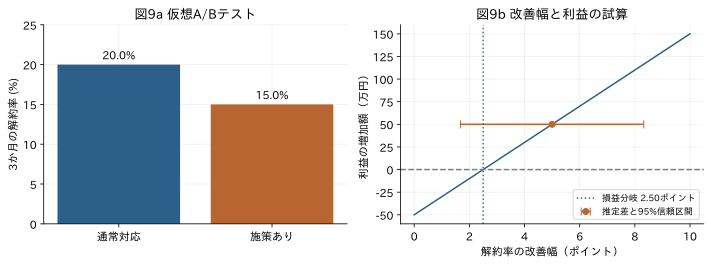

In [14]:
show_math(r"""\(\begin{aligned}
\Pi&=N\Delta r g-Nc\\
&=1000\times0.0500\times20000-1000\times500\\
&=1000000-500000=500000\ \mathrm{yen}\\
\Pi=0&\ \Longleftrightarrow\ N\Delta r g=Nc
\ \Longleftrightarrow\ \Delta r=\frac{c}{g}
=\frac{500}{20000}=0.0250
\end{aligned}\)""")
margin, cost = 20000, 500
profit = n * delta * margin - n * cost
profit_ci = n * ci * margin - n * cost
pprint({"利益の試算（円）": f"{profit:,.0f}",
        "改善幅の区間に対応する利益の幅（万円）": [sig3(v / 10000) for v in profit_ci]})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
bars = axes[0].bar(["通常対応", "施策あり"], [100 * rate_control, 100 * rate_treatment],
                   color=[BLUE, ORANGE])
axes[0].bar_label(bars, labels=["20.0%", "15.0%"], padding=4)
axes[0].set(title="図9a 仮想A/Bテスト", ylabel="3か月の解約率 (%)", ylim=(0, 25))
improvements = np.linspace(0, 0.100, 101)
axes[1].plot(100 * improvements, (n * improvements * margin - n * cost) / 10000, color=BLUE)
axes[1].errorbar(delta * 100, profit / 10000,
                 xerr=[[100 * (delta - ci[0])], [100 * (ci[1] - delta)]],
                 fmt="o", color=ORANGE, capsize=4, label="推定差と95%信頼区間")
axes[1].axhline(0, color="0.500", linestyle="--")
axes[1].axvline(100 * cost / margin, color=GREEN, linestyle=":", label="損益分岐 2.50ポイント")
axes[1].set(title="図9b 改善幅と利益の試算", xlabel="解約率の改善幅（ポイント）", ylabel="利益の増加額（万円）")
axes[1].legend(fontsize=9)
save_svg(fig, "09_ab_profit.svg")

利益の試算は50万円、損益分岐は2.50ポイントになる。解約率の差の区間を利益に換算すると、約−16.5万〜116万円である。追加粗利と費用の仮定を固定した幅であり、黒字を十分に確認した結果ではない。私は、解約率が下がったという報告にも、対象者全員の費用を併記したい。

## 結論

この記事では、生存時間解析で継続期間を調べ、解約スコアで対象候補を選び、施策の効果と採算を別に確認する流れを紹介した。

予測の精度だけで施策の拡大は決められない。本書第7章では、打ち切りやモデルの仮定を確認し、顧客への働きかけを検証するところまで扱う。詳しい説明とコード全体は、[本書](https://gihyo.jp/book/2026/978-4-297-16025-8)と[第7章のサポートノートブック](https://github.com/gihyo-book/marketing_science_book/blob/main/07/07_main.ipynb)を参照できる。

データ出典：IBM, *Telco Customer Churn*（Apache License 2.0）。本書同梱CSVを使用した。